# Smart Outcome Predictor
Ensemble-based system for an EdTech platform: **(1) Classification** - will a student complete the course? **(2) Regression** - what will the final score be?

## Part A - Conceptual Foundation
**1. Ensemble Learning.** Combines several models into one stronger predictor. It works because individual models make different errors; averaging/voting cancels them, lowering variance (and sometimes bias), so results are more accurate and stable.

**2. Bagging vs Boosting vs Voting.** *Bagging* trains the same model on bootstrap samples in parallel and averages them (reduces variance). *Boosting* trains weak learners sequentially, each focusing on the previous errors (reduces bias). *Voting* combines different model types by majority vote (hard) or averaged probabilities (soft).

**3. Bias-Variance Trade-off.** High bias = underfitting (too simple); high variance = overfitting (too sensitive to training data). Bagging cuts variance, boosting cuts bias, stacking/voting balance both by mixing diverse models.

**4. Voting vs Stacking.** Voting combines predictions with a fixed rule (majority / average). Stacking trains a *meta-learner* on the base models' out-of-fold predictions, so it learns how much to trust each model.

**5. AdaBoost vs XGBoost.** AdaBoost re-weights misclassified samples and combines shallow stumps with weighted votes. XGBoost fits each new tree to the gradient of the loss, with regularisation (L1/L2), shrinkage, subsampling, built-in missing-value handling and fast parallel training - usually more accurate and robust.

## Imports

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, pickle, json, warnings
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor, AdaBoostClassifier, AdaBoostRegressor,
                              VotingClassifier, StackingClassifier, StackingRegressor)
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

## Part B - Dataset Understanding & Preparation

In [2]:
df = pd.read_csv("../Datasets/Smart_Outcome_Predictor_Dataset.csv")
print(f"Shape : {df.shape}")
df.head()

Shape : (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             5200 non-null   int64  
 1   age                    5200 non-null   int64  
 2   country_region         5200 non-null   str    
 3   device_type            5200 non-null   str    
 4   education_background   5200 non-null   str    
 5   course_level           5200 non-null   str    
 6   course_category        5200 non-null   str    
 7   course_start_date      5200 non-null   str    
 8   week_of_year           5200 non-null   int64  
 9   sessions               5200 non-null   int64  
 10  time_spent_hours       5088 non-null   float64
 11  videos_watched         5200 non-null   int64  
 12  quiz_attempts          5200 non-null   int64  
 13  assignments_submitted  5200 non-null   int64  
 14  forum_posts            5200 non-null   int64  
 15  avg_quiz_score 

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
student_id,5200.0,702600.500000,1501.255031,700001.000,701300.75000,702600.500,703900.250,705200.0
age,5200.0,24.339615,5.578864,16.000,20.00000,24.000,28.000,45.0
week_of_year,5200.0,26.621538,15.007731,1.000,14.00000,27.000,40.000,52.0
sessions,5200.0,19.121923,10.726708,1.000,11.00000,17.000,25.000,94.0
time_spent_hours,5088.0,18.216156,10.734114,0.600,10.30000,16.100,23.800,76.8
videos_watched,5200.0,25.852885,17.720493,0.000,13.00000,23.000,35.000,158.0
quiz_attempts,5200.0,6.995769,2.568017,0.000,5.00000,7.000,9.000,20.0
assignments_submitted,5200.0,3.835769,1.951802,0.000,2.00000,4.000,5.000,12.0
forum_posts,5200.0,1.585577,1.270640,0.000,1.00000,1.000,2.000,8.0
avg_quiz_score,5119.0,66.842626,13.813992,0.000,57.50000,66.900,76.200,100.0


### B1. Features and targets

In [5]:
T_CLS, T_REG = 'completion_status', 'final_score'
DROP = ['student_id', 'course_start_date']          # identifier / date (week_of_year already captures timing)
FEATURES = [c for c in df.columns if c not in DROP + [T_CLS, T_REG]]   # each target is excluded from the other task's features (no leakage)
CAT = ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
NUM = [c for c in FEATURES if c not in CAT]
print('numeric    :', NUM)
print('categorical:', CAT)
print('Classification target:', T_CLS, '| Regression target:', T_REG)

numeric    : ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
categorical: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
Classification target: completion_status | Regression target: final_score


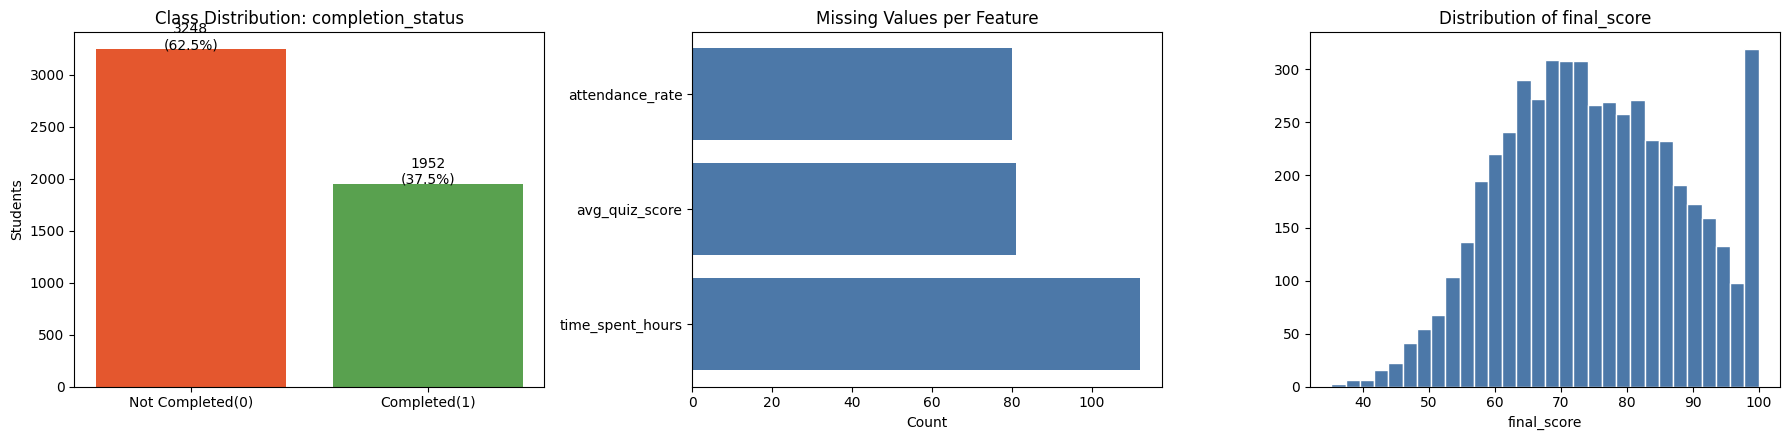

In [6]:
miss = df[FEATURES].isna().sum(); miss = miss[miss > 0]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
vc = df[T_CLS].value_counts().sort_index()
ax[0].bar(['Not Completed(0)', 'Completed(1)'], vc, color=['#E4572E', '#59A14F'])
for i, v in enumerate(vc): ax[0].text(i, v, f'{v}\n({v/len(df):.1%})', ha='center')
ax[0].set_title('Class Distribution: completion_status'); ax[0].set_ylabel('Students')
ax[1].barh(miss.index, miss.values, color='#4C78A8'); ax[1].set_title('Missing Values per Feature'); ax[1].set_xlabel('Count')
ax[2].hist(df[T_REG], bins=30, color='#4C78A8', edgecolor='white'); ax[2].set_title('Distribution of final_score'); ax[2].set_xlabel('final_score')
plt.tight_layout(); plt.savefig('../Images/01_target_distribution_missing.png'); plt.show()

**Interpretation:** 5,200 students; only **37.5% completed** the course (about 1.7 : 1 imbalance, so stratified splitting is used). `time_spent_hours` (112), `avg_quiz_score` (81) and `attendance_rate` (80) have missing values, handled by KNN imputation. `final_score` is centred around 75 with a long left tail of weak performers.

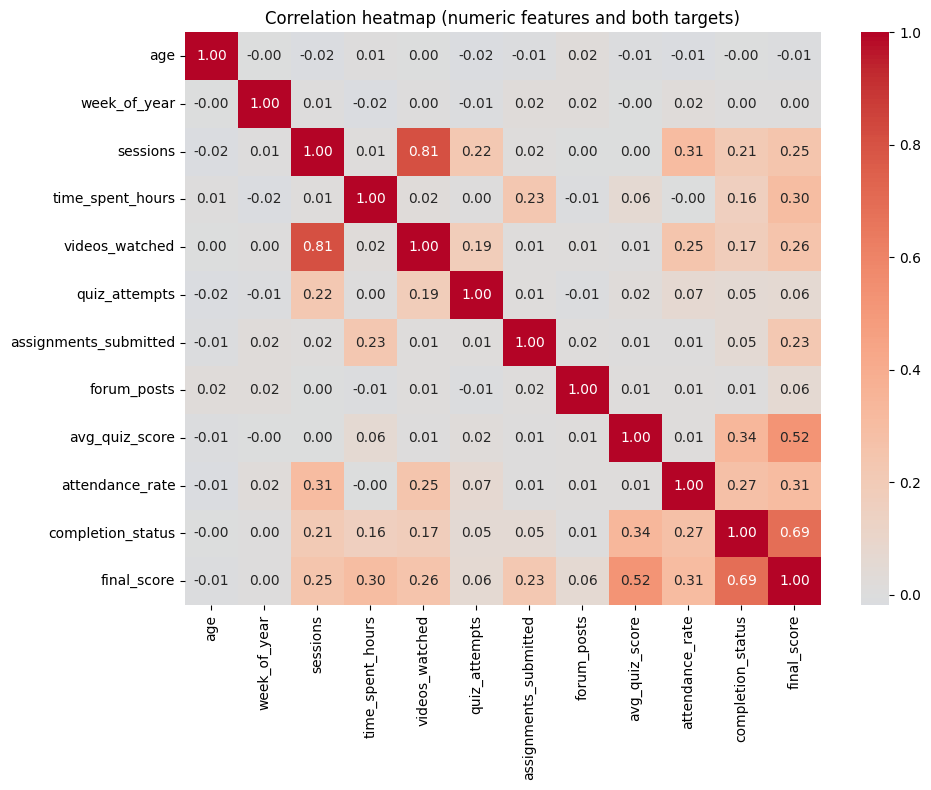

                       completion_status  final_score
avg_quiz_score                     0.343        0.524
attendance_rate                    0.273        0.309
sessions                           0.213        0.248
videos_watched                     0.174        0.255
time_spent_hours                   0.162        0.302
assignments_submitted              0.054        0.226
quiz_attempts                      0.052        0.063
forum_posts                        0.006        0.065
week_of_year                       0.004        0.003
age                               -0.002       -0.009


In [7]:
corr = df.select_dtypes('number').drop(columns='student_id').corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric features and both targets)'); plt.tight_layout()
plt.savefig('../Images/02_correlation_heatmap.png'); plt.show()
print(corr[[T_CLS, T_REG]].drop([T_CLS, T_REG]).round(3).sort_values(T_CLS, ascending=False).to_string())

**Interpretation:** `avg_quiz_score` is the strongest predictor of both completion (+0.34) and final score (+0.52), followed by attendance, sessions, videos watched and time spent. `age`, `week_of_year` and `forum_posts` have almost no linear relationship. Correlations are moderate, so we expect only moderate accuracy (no perfect model).

### B2. Train-test split (same rows for both tasks, stratified on completion_status)

In [8]:
X = df[FEATURES]
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, df[T_CLS], df[T_REG], test_size=0.2, stratify=df[T_CLS], random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Completion rate  train: %.3f | test: %.3f' % (yc_train.mean(), yc_test.mean()))

Train: (4160, 15)  Test: (1040, 15)
Completion rate  train: 0.375 | test: 0.375


### B3. Preprocessing - scaling, KNN imputation (numeric) and constant-fill + one-hot encoding (categorical)

In [9]:
def make_preprocessor():
    num_pipe = Pipeline([('scale', StandardScaler()), ('knn', KNNImputer(n_neighbors=5))])
    cat_pipe = Pipeline([('fill', SimpleImputer(strategy='constant', fill_value='Unknown')),
                         ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', num_pipe, NUM), ('cat', cat_pipe, CAT)])

prep = make_preprocessor()
Xtr = prep.fit_transform(X_train)
Xte = prep.transform(X_test)
print('After preprocessing -> train', Xtr.shape, '| test', Xte.shape, '| NaNs left:', int(np.isnan(Xtr).sum() + np.isnan(Xte).sum()))

After preprocessing -> train (4160, 30) | test (1040, 30) | NaNs left: 0


**Interpretation:** Preprocessing is wrapped in a `ColumnTransformer` (scale + KNN-impute numeric, one-hot categorical) giving 30 model features and zero NaNs. It is fitted on the training set only, so the test set has no leakage. `student_id` and `course_start_date` were dropped, and each target is excluded from the other task's features.

## Helper functions for evaluation (Part F metrics)

In [10]:
cls_rows, reg_rows, cls_models, reg_models = [], [], {}, {}

def eval_cls(name, model):
    model.fit(Xtr, yc_train); pred = model.predict(Xte)
    p = model.predict_proba(Xte)[:, 1] if hasattr(model, 'predict_proba') else pred   # hard voting has no probabilities
    cls_models[name] = model
    cls_rows.append(dict(Model=name, Accuracy=accuracy_score(yc_test, pred), Precision=precision_score(yc_test, pred),
                         Recall=recall_score(yc_test, pred), F1=f1_score(yc_test, pred), AUC=roc_auc_score(yc_test, p),
                         Train_Acc=accuracy_score(yc_train, model.predict(Xtr))))

def eval_reg(name, model):
    model.fit(Xtr, yr_train); pred = model.predict(Xte)
    reg_models[name] = model
    reg_rows.append(dict(Model=name, MAE=mean_absolute_error(yr_test, pred), RMSE=np.sqrt(mean_squared_error(yr_test, pred)),
                         R2=r2_score(yr_test, pred), Train_R2=r2_score(yr_train, model.predict(Xtr))))

## Part C - Bagging (single base model vs Bagging)

In [11]:
eval_cls('Decision Tree', DecisionTreeClassifier(random_state=42))
eval_cls('Bagging Classifier', BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=42, n_jobs=-1))
eval_reg('Decision Tree', DecisionTreeRegressor(random_state=42))
eval_reg('Bagging Regressor', BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=100, oob_score=True, random_state=42, n_jobs=-1))
print('Bagging Classifier OOB accuracy:', round(cls_models['Bagging Classifier'].oob_score_, 4))
print('Bagging Regressor  OOB R2      :', round(reg_models['Bagging Regressor'].oob_score_, 4))
display(pd.DataFrame(cls_rows).round(4)); display(pd.DataFrame(reg_rows).round(4))

Bagging Classifier OOB accuracy: 0.6988
Bagging Regressor  OOB R2      : 0.4508


,Model,Accuracy,Precision,Recall,F1,AUC,Train_Acc
0,Decision Tree,0.6173,0.4903,0.5205,0.5050,0.5979,1.0
1,Bagging Classifier,0.7058,0.6193,0.5590,0.5876,0.7584,1.0


,Model,MAE,RMSE,R2,Train_R2
0,Decision Tree,11.2788,14.1865,-0.1055,1.0000
1,Bagging Regressor,8.3140,10.3033,0.4169,0.9245


**Interpretation:** A single unpruned Decision Tree memorises the training data (train accuracy 1.00) but generalises poorly (test accuracy 0.617, AUC 0.598; regression R2 -0.11). Bagging 100 trees reduces this variance sharply: accuracy 0.706, AUC 0.758, and regression RMSE 14.19 -> 10.30 (R2 0.417). OOB scores (0.699 accuracy, 0.451 R2) agree with test results, giving a free validation estimate.

## Part D - Boosting (AdaBoost & XGBoost)
### D1. AdaBoost

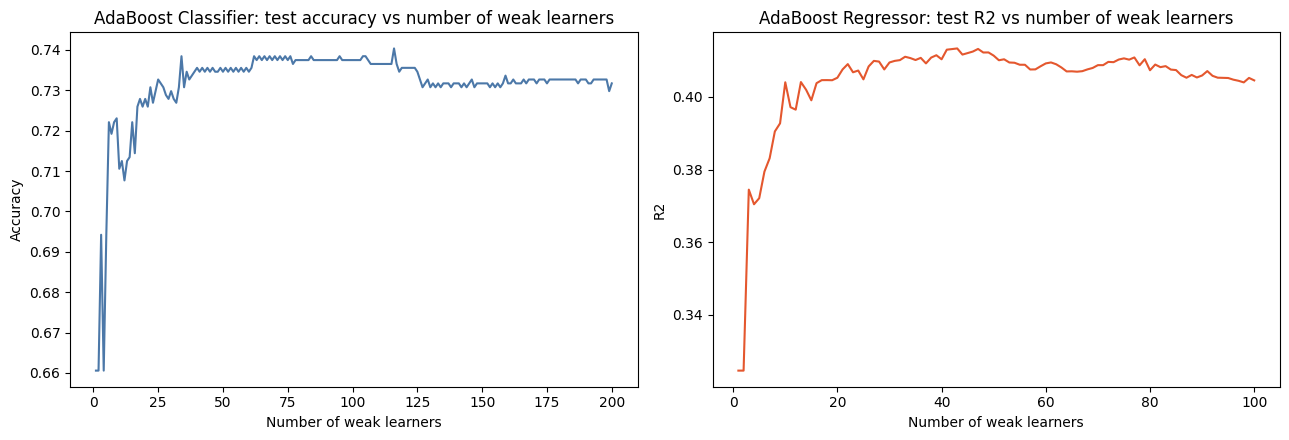

In [12]:
eval_cls('AdaBoost Classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5, random_state=42))
eval_reg('AdaBoost Regressor', AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=100, learning_rate=0.5, random_state=42))
# How weak learners improve sequentially: score after each added learner
ada_c, ada_r = cls_models['AdaBoost Classifier'], reg_models['AdaBoost Regressor']
acc_stage = [accuracy_score(yc_test, p) for p in ada_c.staged_predict(Xte)]
r2_stage = [r2_score(yr_test, p) for p in ada_r.staged_predict(Xte)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(range(1, len(acc_stage)+1), acc_stage, color='#4C78A8'); ax[0].set_title('AdaBoost Classifier: test accuracy vs number of weak learners')
ax[1].plot(range(1, len(r2_stage)+1), r2_stage, color='#E4572E'); ax[1].set_title('AdaBoost Regressor: test R2 vs number of weak learners')
for a, y in zip(ax, ['Accuracy', 'R2']): a.set_xlabel('Number of weak learners'); a.set_ylabel(y)
plt.tight_layout(); plt.savefig('../Images/03_adaboost_sequential.png'); plt.show()

**Interpretation:** Each added weak learner corrects the mistakes of the previous ones, so performance rises quickly in the first tens of learners and then flattens. This is boosting reducing bias sequentially; the flat tail shows extra learners give diminishing returns.

### D2. XGBoost

In [13]:
eval_cls('XGBoost Classifier', XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss'))
eval_reg('XGBoost Regressor', XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42))
display(pd.DataFrame(cls_rows).set_index('Model').loc[['AdaBoost Classifier', 'XGBoost Classifier']].round(4))
display(pd.DataFrame(reg_rows).set_index('Model').loc[['AdaBoost Regressor', 'XGBoost Regressor']].round(4))

,Accuracy,Precision,Recall,F1,AUC,Train_Acc
Model,,,,,,
AdaBoost Classifier,0.7317,0.6762,0.5462,0.6043,0.7876,0.7377
XGBoost Classifier,0.7231,0.6474,0.5744,0.6087,0.7722,0.8353


,MAE,RMSE,R2,Train_R2
Model,,,,
AdaBoost Regressor,8.4908,10.4112,0.4046,0.4949
XGBoost Regressor,8.1952,10.1928,0.4293,0.6746


**Interpretation:** AdaBoost: accuracy 0.732, AUC 0.788, R2 0.405. XGBoost: accuracy 0.723, AUC 0.772, recall 0.574, and the best boosting regressor (RMSE 10.19, R2 0.429). The two are close on classification (AdaBoost has slightly better AUC, XGBoost slightly better recall); XGBoost wins on regression thanks to regularisation, subsampling and deeper trees. XGBoost fits training data more tightly (train acc 0.835 vs test 0.723), so it needs mild regularisation.

## Part E - Voting & Stacking

In [14]:
base_c = [('lr', LogisticRegression(max_iter=2000)), ('knn', KNeighborsClassifier(n_neighbors=7)),
          ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)), ('svm', SVC(probability=True, random_state=42))]
base_r = [('ridge', Ridge()), ('knn', KNeighborsRegressor(n_neighbors=7)),
          ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)), ('svr', SVR())]
eval_cls('Hard Voting', VotingClassifier(base_c, voting='hard'))
eval_cls('Soft Voting', VotingClassifier(base_c, voting='soft'))
eval_cls('Stacking Classifier', StackingClassifier(base_c, final_estimator=LogisticRegression(), cv=5, n_jobs=-1))
eval_reg('Stacking Regressor', StackingRegressor(base_r, final_estimator=Ridge(), cv=5, n_jobs=-1))
display(pd.DataFrame(cls_rows).set_index('Model').loc[['Hard Voting', 'Soft Voting', 'Stacking Classifier']].round(4))
display(pd.DataFrame(reg_rows).set_index('Model').loc[['Stacking Regressor']].round(4))

,Accuracy,Precision,Recall,F1,AUC,Train_Acc
Model,,,,,,
Hard Voting,0.7346,0.7065,0.5000,0.5856,0.6877,0.7627
Soft Voting,0.7394,0.6951,0.5436,0.6101,0.7816,0.7683
Stacking Classifier,0.7394,0.6820,0.5718,0.6220,0.7931,0.7411


,MAE,RMSE,R2,Train_R2
Model,,,,
Stacking Regressor,8.0344,9.9942,0.4513,0.5127


**Interpretation:** Soft voting (accuracy 0.739, AUC 0.782) beats hard voting (AUC 0.688, recall 0.50) because averaging probabilities keeps each model's confidence instead of discarding it. Stacking is best overall (AUC 0.793, F1 0.622, recall 0.572): its Logistic Regression meta-learner learns how much to trust each base model. The Stacking Regressor also leads regression (RMSE 9.99, MAE 8.03, R2 0.451).

## Part F - Model Evaluation & Comparison

In [15]:
cls_tbl = pd.DataFrame(cls_rows).sort_values('AUC', ascending=False).round(4).reset_index(drop=True)
reg_tbl = pd.DataFrame(reg_rows).sort_values('RMSE').round(4).reset_index(drop=True)
cls_tbl.to_csv('../Outputs/classification_results.csv', index=False); reg_tbl.to_csv('../Outputs/regression_results.csv', index=False)
display(cls_tbl); display(reg_tbl)

,Model,Accuracy,Precision,Recall,F1,AUC,Train_Acc
0,Stacking Classifier,0.7394,0.6820,0.5718,0.6220,0.7931,0.7411
1,AdaBoost Classifier,0.7317,0.6762,0.5462,0.6043,0.7876,0.7377
2,Soft Voting,0.7394,0.6951,0.5436,0.6101,0.7816,0.7683
3,XGBoost Classifier,0.7231,0.6474,0.5744,0.6087,0.7722,0.8353
4,Bagging Classifier,0.7058,0.6193,0.5590,0.5876,0.7584,1.0000
5,Hard Voting,0.7346,0.7065,0.5000,0.5856,0.6877,0.7627
6,Decision Tree,0.6173,0.4903,0.5205,0.5050,0.5979,1.0000


,Model,MAE,RMSE,R2,Train_R2
0,Stacking Regressor,8.0344,9.9942,0.4513,0.5127
1,XGBoost Regressor,8.1952,10.1928,0.4293,0.6746
2,Bagging Regressor,8.3140,10.3033,0.4169,0.9245
3,AdaBoost Regressor,8.4908,10.4112,0.4046,0.4949
4,Decision Tree,11.2788,14.1865,-0.1055,1.0000


**Interpretation:** Classification ranking by AUC: Stacking (0.793) > AdaBoost (0.788) > Soft Voting (0.782) > XGBoost (0.772) > Bagging (0.758) > Hard Voting (0.688) > Decision Tree (0.598). Regression ranking by RMSE: Stacking (9.99) > XGBoost (10.19) > Bagging (10.30) > AdaBoost (10.41) > Decision Tree (14.19). Every ensemble beats the single tree; the top models are separated by small margins.

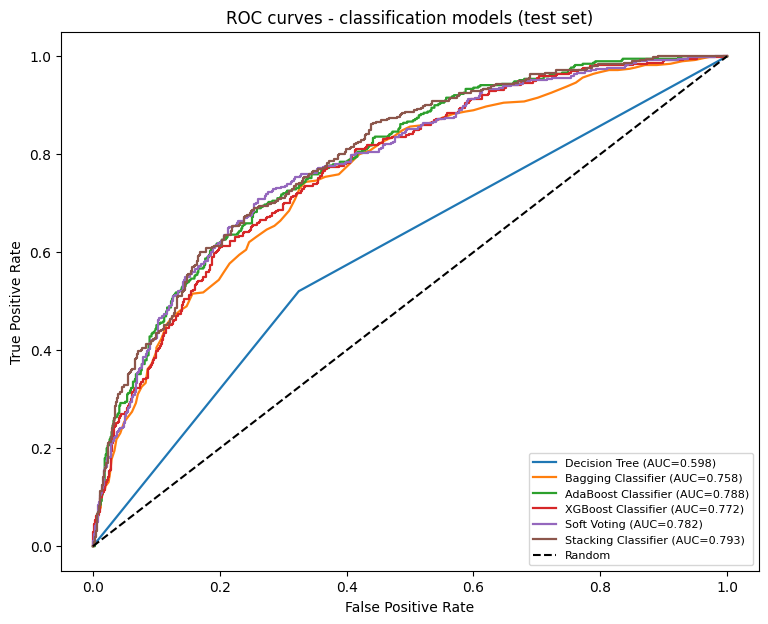

In [16]:
plt.figure(figsize=(9, 7))
for n, m in cls_models.items():
    if n == 'Hard Voting': continue
    p = m.predict_proba(Xte)[:, 1]; fpr, tpr, _ = roc_curve(yc_test, p)
    plt.plot(fpr, tpr, lw=1.6, label=f"{n} (AUC={roc_auc_score(yc_test, p):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves - classification models (test set)'); plt.legend(loc='lower right', fontsize=8)
plt.savefig('../Images/04_roc_curves.png'); plt.show()

**Interpretation:** Stacking, AdaBoost and Soft Voting curves are the highest and nearly overlap; the single Decision Tree is close to the diagonal (weak ranking ability). Ensembles clearly separate completers from non-completers better than a single tree.

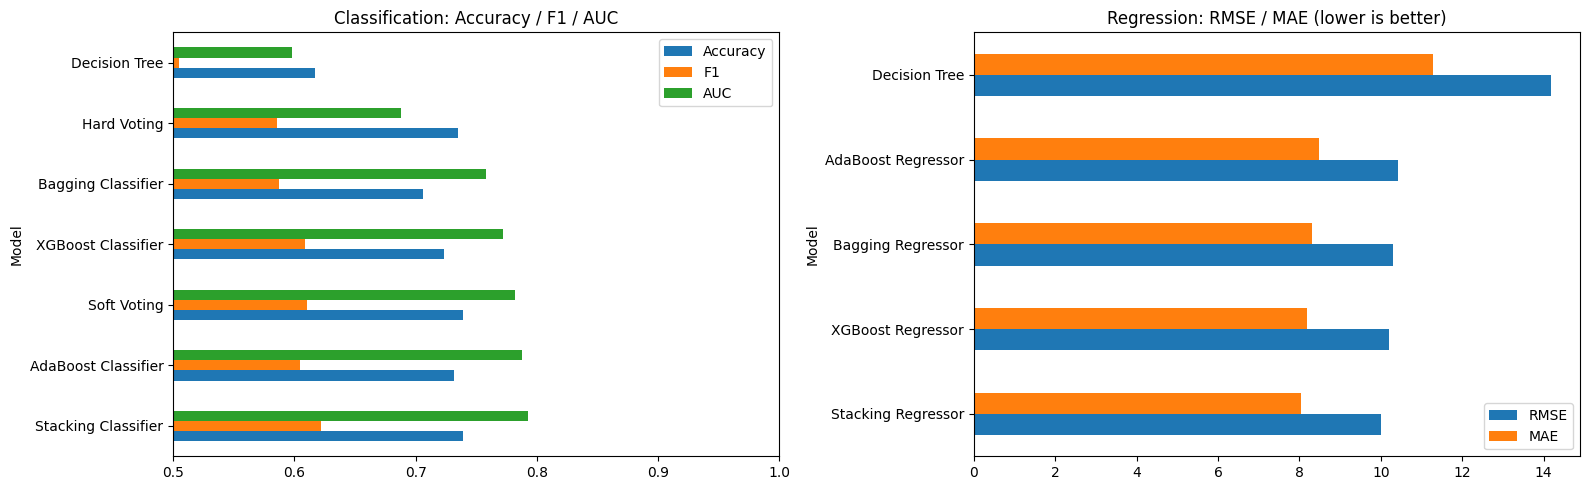

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
cls_tbl.set_index('Model')[['Accuracy', 'F1', 'AUC']].plot.barh(ax=ax[0]); ax[0].set_xlim(0.5, 1); ax[0].set_title('Classification: Accuracy / F1 / AUC')
reg_tbl.set_index('Model')[['RMSE', 'MAE']].plot.barh(ax=ax[1]); ax[1].set_title('Regression: RMSE / MAE (lower is better)')
plt.tight_layout(); plt.savefig('../Images/05_model_comparison.png'); plt.show()

**Interpretation:** The bars confirm that ensembles beat the Decision Tree on every metric, and that Stacking leads both tasks. Differences among Stacking, boosting and soft voting are small (about 0.01 AUC / 0.2-0.4 RMSE).

Best classifier (highest AUC): Stacking Classifier
Best regressor  (lowest RMSE): Stacking Regressor


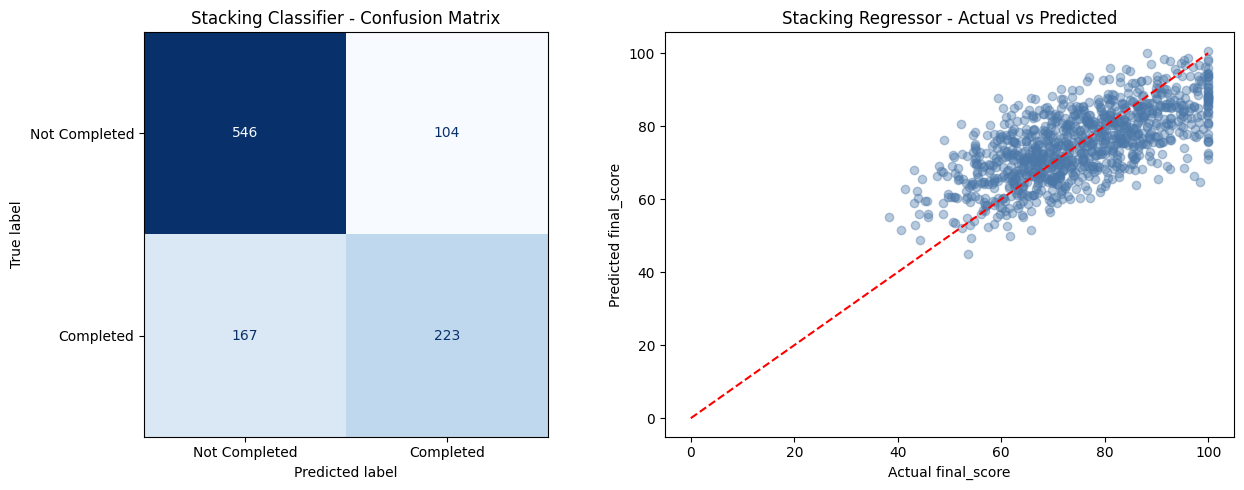

In [18]:
best_cls, best_reg = cls_tbl.loc[0, 'Model'], reg_tbl.loc[0, 'Model']
print('Best classifier (highest AUC):', best_cls); print('Best regressor  (lowest RMSE):', best_reg)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(yc_test, cls_models[best_cls].predict(Xte)), display_labels=['Not Completed', 'Completed']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title(f'{best_cls} - Confusion Matrix'); ax[0].grid(False)
ax[1].scatter(yr_test, reg_models[best_reg].predict(Xte), alpha=0.4, color='#4C78A8'); ax[1].plot([0, 100], [0, 100], 'r--')
ax[1].set_xlabel('Actual final_score'); ax[1].set_ylabel('Predicted final_score'); ax[1].set_title(f'{best_reg} - Actual vs Predicted')
plt.tight_layout(); plt.savefig('../Images/06_best_models.png'); plt.show()

**Interpretation:** The Stacking Classifier correctly classifies about 74% of students, but it misses a share of completers (recall 0.57), a limit of the available features. The regression plot shows predictions follow the diagonal but are compressed toward the mean (R2 0.45), with larger errors for very high and very low scores.

## Part G - Final Pipelines, Pickle files & Report

In [19]:
# Final end-to-end pipelines (preprocessing + best model) fitted on RAW training data
cls_pipe = Pipeline([('prep', make_preprocessor()), ('clf', clone(cls_models[best_cls]))]).fit(X_train, yc_train)
reg_pipe = Pipeline([('prep', make_preprocessor()), ('reg', clone(reg_models[best_reg]))]).fit(X_train, yr_train)
pc, pp, pr = cls_pipe.predict(X_test), cls_pipe.predict_proba(X_test)[:, 1], reg_pipe.predict(X_test)
cm = dict(Accuracy=accuracy_score(yc_test, pc), Precision=precision_score(yc_test, pc), Recall=recall_score(yc_test, pc),
          F1=f1_score(yc_test, pc), AUC=roc_auc_score(yc_test, pp))
rm = dict(MAE=mean_absolute_error(yr_test, pr), RMSE=np.sqrt(mean_squared_error(yr_test, pr)), R2=r2_score(yr_test, pr))

pickle.dump(cls_pipe, open('../Models/completion_pipeline.pkl', 'wb'))
pickle.dump(reg_pipe, open('../Models/score_pipeline.pkl', 'wb'))
info = {'classifier': best_cls, 'regressor': best_reg,
        'classification_metrics': {k: round(float(v), 4) for k, v in cm.items()},
        'regression_metrics': {k: round(float(v), 4) for k, v in rm.items()},
        'features': FEATURES, 'num': NUM, 'cat': CAT,
        'cat_options': {c: sorted(df[c].unique().tolist()) for c in CAT},
        'num_ranges': {c: [float(df[c].min()), float(df[c].max()), float(df[c].median())] for c in NUM},
        'all_classification': cls_tbl.to_dict('records'), 'all_regression': reg_tbl.to_dict('records')}
json.dump(info, open('../Models/final_metrics.json', 'w'), indent=4)
print(info['classifier'], info['classification_metrics']); print(info['regressor'], info['regression_metrics'])
print('Saved: Models/completion_pipeline.pkl, Models/score_pipeline.pkl, Models/final_metrics.json')

Stacking Classifier {'Accuracy': 0.7394, 'Precision': 0.682, 'Recall': 0.5718, 'F1': 0.622, 'AUC': 0.7931}
Stacking Regressor {'MAE': 8.0344, 'RMSE': 9.9942, 'R2': 0.4513}
Saved: Models/completion_pipeline.pkl, Models/score_pipeline.pkl, Models/final_metrics.json


In [20]:
# Quick check: reload pickles and predict one unseen student
c = pickle.load(open('../Models/completion_pipeline.pkl', 'rb')); r = pickle.load(open('../Models/score_pipeline.pkl', 'rb'))
new = X_test.iloc[[0]]
print('Completion probability:', round(float(c.predict_proba(new)[0, 1]), 3), '| Predicted score:', round(float(r.predict(new)[0]), 1),
      '| Actual:', int(yc_test.iloc[0]), yr_test.iloc[0])

Completion probability: 0.629 | Predicted score: 78.9 | Actual: 0 68.0


## Final Report

**1. Bagging vs Boosting.** Bagging mainly reduces variance: it lifted the Decision Tree from AUC 0.598 to 0.758 and cut regression RMSE from 14.19 to 10.30, but its trees still fit training data perfectly (train acc 1.00). Boosting reduces bias sequentially with weak learners and gives better test results with a smaller train-test gap (AdaBoost AUC 0.788, XGBoost RMSE 10.19). Boosting was slightly better than bagging on both tasks.

**2. Tree-based boosting comparison.** AdaBoost (stumps) is simple and competitive for classification (AUC 0.788) but is the weakest ensemble regressor (RMSE 10.41). XGBoost is the best boosting regressor (R2 0.429) and has better recall (0.574) thanks to regularisation, shrinkage and subsampling; it is more tunable but overfits more if left unconstrained.

**3. Voting and Stacking.** Soft voting beats hard voting (AUC 0.782 vs 0.688) because it uses probabilities. Stacking is the best on both tasks (AUC 0.793, F1 0.622; RMSE 9.99, R2 0.451) because the meta-learner weights diverse base models (linear, KNN, tree, SVM). Cost: longer training and more complex deployment.

**4. Final recommendation.** Deploy the **Stacking Classifier** (completion) and **Stacking Regressor** (final score), packaged as full preprocessing pipelines (`completion_pipeline.pkl`, `score_pipeline.pkl`). If simplicity or speed matters, XGBoost is a close, cheaper alternative (AUC 0.772, RMSE 10.19). Do not use a single Decision Tree.

**5. Business interpretation.** The platform can flag students with a low completion probability (accuracy 74%, precision 0.68) for early support such as reminders, mentoring and quiz help, and forecast final scores within about 8 points on average (MAE 8.0). Engagement and quiz performance (`avg_quiz_score`, attendance, sessions) are the strongest drivers, so interventions should focus there. Recall is only 0.57, so the tool should support, not replace, human review; adding richer data (e.g. weekly progress trends) is the best way to improve it.